# Sentinel-2 quality screening: at most 15 scenes per field-month

This notebook applies one fixed image-quality policy to individual sampled Level-2A Sentinel-2 scenes. The private full database contains those observations in raw_v1 and raw_oaf5. They are scene metadata and sampled band/pixel values, not complete image rasters. The old standalone database is not needed; the ready-made monthly_clearest and monthly_median tables are not used for selection.

The sequence is: official unlocked development field IDs → sampled scenes from both archive years → cloud, band, pixel and timing checks → 100-point quality score → independent-overflight ordering → up to 15 qualifying scenes per field-month → median bands of those selected scenes → one seasonal model row per field. Yield and model predictions never enter image ranking.

| Notebook step | Implementation in the companion script | Auditable output |
|---|---|---|
| Source and cohort | quality_screen.py: scope_fields, candidates | Database inventory and candidate counts below |
| Optical checks | quality_screen.py: polygon_clear, decisions | scene_decisions.parquet |
| Score and rank | quality_screen.py: monthly_top | monthly_top15.parquet |
| Missing months | quality_screen.py: monthly_coverage | monthly_coverage.parquet |
| Model features | top15_features.py: monthly, in_scope, seasonal | top15_model_ready.parquet |

In [1]:
from pathlib import Path
import json, subprocess, sys
import duckdb, pandas as pd, matplotlib.pyplot as plt
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/"data/team_data_full_v1.duckdb").is_file()), None)
assert ROOT is not None, "Put the private database in data/ and run from the repository."
DB = ROOT/"data/team_data_full_v1.duckdb"
OUT = ROOT/"data/clean"
SCHEMAS = ("raw_v1","raw_oaf5")
con = duckdb.connect(str(DB), read_only=True)
print("Database:",DB.name,"Raw schemas:",SCHEMAS)

Database: team_data_full_v1.duckdb Raw schemas: ('raw_v1', 'raw_oaf5')


## 1. Check the source and eligible fields

The root README requires all included countries and years, while keeping sealed rows out of analysis. The official labels and folds_all tables define the development cohort: maize, keep = true, locked = false, fold 1–4. Nigeria has no eligible development fields. These fields determine scope, not the optical quality score.

The ordinary SHOW TABLES command lists only the default schema. The next cell explicitly counts the raw tables in both nested schemas. The raw_oaf5 pixel_samples table is empty, but its fields are points; the polygon SCL-pixel calculation applies to raw_v1 polygons.

In [2]:
inventory = con.execute("""
SELECT l.country_iso3, min(l.season_year) first_year, max(l.season_year) last_year,
       count(*) maize_rows,
       count(*) FILTER(WHERE l.keep AND NOT f.locked AND f.fold BETWEEN 1 AND 4) development_fields
FROM labels l LEFT JOIN folds_all f ON f.release=l.release AND f.field_season_id=l.field_season_id
WHERE l.crop='maize' GROUP BY 1 ORDER BY 1
""").df()
display(inventory)
print("Development fields:",int(inventory.development_fields.sum()))

,country_iso3,first_year,last_year,maize_rows,development_fields
0,BDI,2015,2020,6377,831
1,KEN,2016,2020,24063,15315
2,MWI,2020,2023,3390,2011
3,NGA,2022,2022,115,0
4,RWA,2016,2020,7205,967
5,TZA,2016,2020,7949,1579
6,UGA,2020,2020,246,196
7,ZMB,2018,2020,1870,1035
8,ZWE,2022,2024,7324,3645


Development fields: 25579


In [3]:
raw_tables=[]
for schema in SCHEMAS:
    for table in ("fields","passes","pass_samples","pixel_samples"):
        raw_tables.append({"schema":schema,"table":table,
                           "rows":con.execute(f"SELECT count(*) FROM {schema}.{table}").fetchone()[0]})
display(pd.DataFrame(raw_tables))

,schema,table,rows
0,raw_v1,fields,35510
1,raw_v1,passes,8248916
2,raw_v1,pass_samples,10757700
3,raw_v1,pixel_samples,259808279
4,raw_oaf5,fields,59604
5,raw_oaf5,passes,2462867
6,raw_oaf5,pass_samples,2709837
7,raw_oaf5,pixel_samples,0


## 2. Exact candidate checks

Sentinel-2's Scene Classification Layer (`SCL`) labels pixels as vegetation, bare soil, cloud, shadow, water, and other classes. This is a classification supplied with the satellite product; the script does not visually inspect an image or train a new cloud detector.

| Check | Data and exact rule | Decision |
|---|---|---|
| Local obstruction at a GPS point | Read the point's `scl`. Classes 4 (vegetation) and 5 (bare soil) are clear. Classes 0, 1, 2, 3, 8, 9, 10, and 11 indicate no data, defective/dark pixels, shadow, clouds, cirrus, or snow. | The latter classes are `reject`. Class 6 (water), class 7 (unclassified), and missing SCL are `review`. Bare soil is not rejected merely for being bare. |
| Required spectral bands | Require non-null raw digital numbers greater than zero for B02, B03, B04, B05, B06, B07, B08, B8A, B11, and B12, plus at least one sampled pixel. The input pass must also have `sample_status = 'sampled_all_bands'`. | `reject` if any requirement fails. This is a data-validity check, not a claim that every positive reflectance value is scientifically perfect. |
| Clear fraction inside a mapped polygon | Join individual 20 m SCL pixels to the stored field footprint. Compute `number of SCL 4 or 5 pixels / number of sampled SCL pixels in the footprint`. A single polygon-level summary SCL value is not used for this fraction. | `reject` below 0.80; `review` if the fraction cannot be calculated. |
| Local cloud probability | Read sampled `cld` on its 0–100 scale. | `review` at 60 or above. Lower values contribute to the ranking score. Missing values are not treated as zero cloud. |
| Sun elevation | Read `sun_elevation` from scene metadata. | `review` below 30 degrees. Higher values contribute to the score; missing values receive a neutral score. |
| Crop timing | Compare `sensing_time_utc` with recorded `planting_date` and `harvest_date`. | Label each scene `before_planting`, `within_recorded_dates`, `after_harvest`, or `dates_incomplete`. Only scenes within recorded dates or with incomplete dates may enter the top 15. |
| Whole-scene cloud cover | Read `scene_cloud_cover_percent`. This describes the whole scene, which can disagree with cloud conditions at the field. | Used for ranking only; it is not a hard rejection threshold. |

The `keep`, `review`, and `reject` decisions describe optical quality. A scene can be optically clear but outside the recorded crop dates; it remains in the audit table but does not enter the top-15 table.

For a GPS point, `local_clear_fraction = 1` only means that its sampled pixel has SCL class 4 or 5. It does **not** establish that the pixel lies entirely inside the intended field. Point records carry `spatial_support = field_boundary_unverified`.



**Code correspondence:** quality_screen.py first constructs candidates from source passes with sample_status = sampled_all_bands and scene level L2A. The later decisions table implements the rules above. Records that were never successfully sampled are not called cloudy by this table. SCL is the product's scene-classification layer; CLD is the sampled 0–100 local cloud probability. The whole-scene cloud statistic covers a much larger area. Ten positive band values check input availability, not whether a crop is healthy or a picture looks sharp.

In [4]:
screen={}
for schema in SCHEMAS:
    folder=OUT/f"top15_dev_{schema}"
    if not (folder/"summary.json").is_file():
        subprocess.run([sys.executable,str(ROOT/"notebook/Allen/quality_screen.py"),
                        "--database",str(DB),"--schema",schema,"--output",str(folder),
                        "--window-kind","both","--crop","maize"],cwd=ROOT,check=True)
    info=json.loads((folder/"summary.json").read_text(encoding="utf-8"))
    assert (info["schema"],info["crop"],info["window_kind"],info["top_k"])==(schema,"maize","both",15)
    assert info["cohort"]=="official kept, unlocked development folds 1-4"
    screen[schema]=info
display(pd.DataFrame([{"schema":s,"fields":x["scope_fields"],"candidates":x["candidate_rows"],
"kept":x["decisions"].get("keep",0),"review":x["decisions"].get("review",0),
"rejected":x["decisions"].get("reject",0),"selected":x["selected_scenes"]} for s,x in screen.items()]))

,schema,fields,candidates,kept,review,rejected,selected
0,raw_v1,20971,3344793,2060002,41782,1243009,775944
1,raw_oaf5,4608,780126,402784,17008,360334,152767


In [5]:
decision_paths=[str(OUT/f"top15_dev_{s}/scene_decisions.parquet") for s in SCHEMAS]
reasons=con.execute("""
SELECT geometry_type,decision,primary_reason,count(*) AS candidates
FROM read_parquet(?) GROUP BY 1,2,3 ORDER BY 1,2,4 DESC
""",[decision_paths]).df()
display(reasons)
print("Candidate rows examined:",int(reasons.candidates.sum()))

,geometry_type,decision,primary_reason,candidates
0,point,keep,optically_clear,2398431
1,point,reject,local_scl_obstruction,1526735
2,point,reject,missing_or_invalid_band,386
3,point,review,local_scl_uncertain_or_water,58790
4,polygon,keep,optically_clear,64355
5,polygon,reject,insufficient_clear_field_pixels,76205
6,polygon,reject,missing_or_invalid_band,17


Candidate rows examined: 4124919


### Polygon clear fraction: actual sampled pixels

For mapped polygons, the code joins 20 m SCL samples to the stored field footprint and divides the count of classes 4 and 5 by all sampled SCL pixels. A summary SCL class is not used as that denominator. The next cell checks real polygon records against the displayed fraction. Point locations instead have one sampled SCL pixel, so a clear point gets local_clear_fraction = 1 without proving the entire field is clear.

In [6]:
poly=con.execute("""
SELECT field_season_id,scene_id,scl_pixels,clear_pixels,
       local_clear_fraction,decision,primary_reason
FROM read_parquet(?)
WHERE geometry_type='polygon' AND scl_pixels>=3
ORDER BY field_season_id,scene_id LIMIT 8
""",[decision_paths[0]]).df()
display(poly)
assert ((poly.clear_pixels/poly.scl_pixels-poly.local_clear_fraction).abs()<1e-9).all()

,field_season_id,scene_id,scl_pixels,clear_pixels,local_clear_fraction,decision,primary_reason
0,fs_002825c6741f8dee,S2A_MSIL2A_20210108T074311_N0500_R092_T36LWL_2...,18,0,0.0,reject,insufficient_clear_field_pixels
1,fs_002825c6741f8dee,S2A_MSIL2A_20210118T074241_N0500_R092_T36LWL_2...,18,0,0.0,reject,insufficient_clear_field_pixels
2,fs_002825c6741f8dee,S2A_MSIL2A_20210128T074201_N0500_R092_T36LWL_2...,18,18,1.0,keep,optically_clear
3,fs_002825c6741f8dee,S2A_MSIL2A_20210207T074101_N0500_R092_T36LWL_2...,18,0,0.0,reject,insufficient_clear_field_pixels
4,fs_002825c6741f8dee,S2A_MSIL2A_20210217T074001_N0500_R092_T36LWL_2...,18,0,0.0,reject,insufficient_clear_field_pixels
5,fs_002825c6741f8dee,S2A_MSIL2A_20210227T073851_N0500_R092_T36LWL_2...,18,0,0.0,reject,insufficient_clear_field_pixels
6,fs_002825c6741f8dee,S2A_MSIL2A_20210309T073741_N0500_R092_T36LWL_2...,18,0,0.0,reject,insufficient_clear_field_pixels
7,fs_002825c6741f8dee,S2A_MSIL2A_20210319T073621_N0500_R092_T36LWL_2...,18,0,0.0,reject,insufficient_clear_field_pixels


## 3. Scoring, ranking and visual examples

Only `keep` observations with acceptable or incomplete crop-date information are scored. The preliminary score is at most 100 points:

| Factor | Maximum points | Calculation |
|---|---:|---|
| Local clear fraction | 50 | `50 × local_clear_fraction` |
| Local cloud probability | 25 | `25 × (1 − cld / 100)` |
| Whole-scene cloud cover | 10 | `10 × (1 − scene_cloud_cover_percent / 100)` |
| Crop timing | 10 | 10 within recorded dates; 5 if dates are incomplete |
| Sun elevation | 5 | `5 × clamp((sun_elevation − 30) / 40, 0, 1)` |

Cloud percentages are clamped to 0–100 before scoring. A missing local cloud probability, scene cloud percentage, or sun elevation receives half of that factor's available points. These weights are a transparent starting policy, not weights optimized against yield labels.

### Worked visual example

The following **synthetic example** shows a mapped field with 8 clear pixels out of 10, so its clear fraction is 80% and it meets the default gate. If its local cloud probability is 20%, whole-scene cloud cover is 30%, acquisition is within the recorded crop dates, and sun elevation is 50 degrees, its score is `40 + 20 + 7 + 10 + 2.5 = 79.5`. A higher cloud probability would produce fewer points. These numbers illustrate the calculation; they are not measurements from the project database.

![A synthetic field-pixel grid and a breakdown of its 79.5-point image-quality score](figures/image_quality_screening_example.png)

### Real scenes: selected, unselected, review, and rejected

The next comparison uses **four real Sentinel-2 scenes of the same Zimbabwe maize-field GPS point in April 2024**. Each column shows a true-color view of the same approximately 640 × 640 m area and its SCL classification map. The magenta ring marks the sampled point. The surrounding square is visual context, **not** a verified field boundary; the point-level decision was based on the sampled pixel and scene metadata.

![Four real Sentinel-2 views of one field point: selected, clear but outside the top 15, review, and cloud-rejected](figures/real_scene_quality_gallery.png)

| Scene date and status | What the database records | Why it received that status |
|---|---|---|
| 18 April — **selected, rank 1** | Point SCL 4 (vegetation), local CLD 0%; clear RGB view. | Passed optical checks and ranked first for this field-month. |
| 25 April — **clear, not in top 15** | Point SCL 5 (bare soil), local CLD 0%; visually clear. | This scene passed the optical checks, but the monthly cap and preference for distinct overflights placed another tile from its overflight ahead of it. It is **not** a rejected image. |
| 28 April — **review** | Point SCL 7 (uncertain/unclassified), local CLD 2%, whole-scene cloud cover about 77%. | The point's SCL classification is uncertain even though its sampled cloud probability is low. The image is held for review and cannot fill a top-15 slot. |
| 13 April — **rejected** | Point SCL 9 (high-probability cloud), local CLD 100%; the RGB view is white. | Cloud is classified at the sampled point, so the observation fails the optical gate. |

These are actual scene excerpts retrieved using the asset links stored in the source database. The RGB panels use one fixed display stretch for comparability. They illustrate the decisions but do not replace the underlying pixel-level rules. The gallery can be regenerated with [`render_real_scene_gallery.py`](figures/render_real_scene_gallery.py), which reads small windows from the public scene assets. Contains modified Copernicus Sentinel data (2024), via Element 84 Earth Search.

Candidates are grouped by `field_season_id`, acquisition year, and acquisition month. The highest-scoring scene from each distinct satellite overflight ranks first. If fewer than 15 independent overflights are available, other eligible scenes from those overflights can fill remaining slots. `same_overflight_rank > 1` identifies such additional scenes. Ties are resolved deterministically using local clear fraction, cloud metrics, acquisition time, and scene ID. The output contains **up to** 15 scenes per field-month; it never adds `review` or `reject` scenes to reach 15.



**Code correspondence:** quality_screen.py creates monthly_top from decision = keep and acceptable or incomplete crop dates. It applies the exact 50/25/10/10/5 formula above. Missing cloud or sun metadata receives half-credit. It gives the first qualifying product from each overflight priority before using any extra tile from a repeated overflight. The figures illustrate the rule; the next cells verify score and statuses against this notebook's actual output.

In [7]:
score_path=str(OUT/"top15_dev_raw_v1/monthly_top15.parquet")
r=con.execute("""
SELECT local_clear_fraction,cld,scene_cloud_cover_percent,timing_flag,
       sun_elevation,quality_score
FROM read_parquet(?)
WHERE field_season_id='fs_8bb6af24617e488c'
  AND item_id='S2A_T35KRA_20240418T082125_L2A'
""",[score_path]).df().iloc[0]
clamp=lambda x,lo,hi:max(lo,min(hi,float(x)))
parts={
 "local clear":50*clamp(r.local_clear_fraction,0,1),
 "local cloud":25*(0.5 if pd.isna(r.cld) else 1-clamp(r.cld,0,100)/100),
 "scene cloud":10*(0.5 if pd.isna(r.scene_cloud_cover_percent) else
                   1-clamp(r.scene_cloud_cover_percent,0,100)/100),
 "crop timing":10 if r.timing_flag=="within_recorded_dates" else 5,
 "sun":5*(0.5 if pd.isna(r.sun_elevation) else clamp((r.sun_elevation-30)/40,0,1))
}
display(pd.DataFrame({"factor":list(parts),"points":list(parts.values())}))
print("Recalculated",round(sum(parts.values()),3),"stored",r.quality_score)
assert abs(round(sum(parts.values()),3)-r.quality_score)<0.001

,factor,points
0,local clear,50.000000
1,local cloud,25.000000
2,scene cloud,9.998165
3,crop timing,5.000000
4,sun,2.909088


Recalculated 92.907 stored 92.907


In [8]:
field_id="fs_8bb6af24617e488c"
items=["S2A_T35KRA_20240418T082125_L2A",
       "S2A_T35KRA_20240425T081135_L2A",
       "S2A_T35KRA_20240428T082125_L2A",
       "S2B_T35KRA_20240413T082123_L2A"]
gallery=con.execute("""
SELECT d.item_id,d.decision,d.primary_reason,d.scl,d.cld,
       round(d.scene_cloud_cover_percent,1) AS scene_cloud,
       t.quality_rank,t.quality_score
FROM read_parquet(?) d LEFT JOIN read_parquet(?) t
 ON d.field_season_id=t.field_season_id AND d.scene_id=t.scene_id
WHERE d.field_season_id=? AND d.item_id IN (?,?,?,?)
""",[decision_paths[0],score_path,field_id,*items]).df().set_index("item_id").loc[items]
display(gallery)
assert gallery.decision.tolist()==["keep","keep","review","reject"]
assert gallery.quality_rank.iloc[0]==1 and gallery.quality_rank.iloc[1:].isna().all()

,decision,primary_reason,scl,cld,scene_cloud,quality_rank,quality_score
item_id,,,,,,,
S2A_T35KRA_20240418T082125_L2A,keep,optically_clear,4.0,0.0,0.0,1,92.907
S2A_T35KRA_20240425T081135_L2A,keep,optically_clear,5.0,0.0,0.0,<NA>,NaN
S2A_T35KRA_20240428T082125_L2A,review,local_scl_uncertain_or_water,7.0,2.0,77.0,<NA>,NaN
S2B_T35KRA_20240413T082123_L2A,reject,local_scl_obstruction,9.0,100.0,100.0,<NA>,NaN


## 4. Verify the monthly cap and independent overflights

The selected table is grouped by field, acquisition year and month. Rank 1 is the first choice. All qualifying first products from independent overflights rank before additional products from a repeated overflight. same_overflight_rank greater than 1 identifies those extras. Review and reject rows never fill a shortage. The coverage table retains every scheduled month, including those without a selected scene.

In [9]:
paths=[str(OUT/f"top15_dev_{s}/monthly_top15.parquet") for s in SCHEMAS]
display(con.execute("""SELECT country_iso3,count(*) selected_scenes,
count(DISTINCT field_season_id) fields_with_scene,max(quality_rank) largest_rank
FROM read_parquet(?) GROUP BY 1 ORDER BY 1""",[paths]).df())
violations=con.execute("""SELECT count(*) FROM (
SELECT field_season_id,year,month,count(*) n,count(DISTINCT quality_rank) u
FROM read_parquet(?) GROUP BY 1,2,3 HAVING n>15 OR n<>u)""",[paths]).fetchone()[0]
assert violations==0
print("Field-months with >15 scenes or duplicate ranks:",violations)

,country_iso3,selected_scenes,fields_with_scene,largest_rank
0,BDI,4958,804,8
1,KEN,377228,15274,15
2,MWI,82301,2011,15
3,RWA,9505,944,15
4,TZA,65152,1578,15
5,UGA,6890,196,15
6,ZMB,66262,1033,15
7,ZWE,316415,3645,15


Field-months with >15 scenes or duplicate ranks: 0


In [10]:
coverage_paths=[str(OUT/f"top15_dev_{s}/monthly_coverage.parquet") for s in SCHEMAS]
support=con.execute("""
SELECT selected_scenes,count(*) AS field_months
FROM read_parquet(?) GROUP BY 1 ORDER BY 1
""",[coverage_paths]).df()
display(support)
assert support.selected_scenes.between(0,15).all()
display(con.execute("""
SELECT same_overflight_rank,count(*) AS selected_records
FROM read_parquet(?) GROUP BY 1 ORDER BY 1
""",[paths]).df())

,selected_scenes,field_months
0,0,381619
1,1,33910
2,2,54010
3,3,35576
4,4,35079
5,5,20720
6,6,23078
7,7,3217
8,8,7967
9,9,1853


,same_overflight_rank,selected_records
0,1,747468
1,2,171179
2,3,6530
3,4,3534


## 5. Aggregate only the selected scenes for modeling

The image-selection output is monthly_top15.parquet. The feature code converts selected digital numbers using (DN + scene offset) / 10,000, then takes each band's median across those **selected** scenes within a month. This is how one monthly feature vector is made; it does not replace or re-rank an image.

The seasonal summary averages monthly bands over valid recorded planting-to-harvest dates. If dates are incomplete or implausible, it flags window_rule = harvest_calendar_year and uses that calendar year provisionally. Missing months remain null, never zero. Out-of-range converted reflectances are counted but do not silently alter the selected top 15. Yield and official fold metadata are joined only after image features are fixed. Fit model imputation and scaling inside each training fold, using the root README's locked and gap rules.

In [11]:
tables=[]
for schema in SCHEMAS:
    folder=OUT/f"top15_dev_features_{schema}"
    if not (folder/"model_ready.parquet").is_file():
        subprocess.run([sys.executable,str(ROOT/"notebook/Allen/top15_features.py"),
                        "--database",str(DB),"--schema",schema,
                        "--top15",str(OUT/f"top15_dev_{schema}/monthly_top15.parquet"),
                        "--output",str(folder)],cwd=ROOT,check=True)
    info=json.loads((folder/"summary.json").read_text(encoding="utf-8"))
    assert info["selected_scenes"]==screen[schema]["selected_scenes"]
    tables.append(pd.read_parquet(folder/"model_ready.parquet"))
ready=pd.concat(tables,ignore_index=True)
expected=int(inventory.development_fields.sum())
assert len(ready)==expected and ready.field_season_id.is_unique
assert ready.fold.between(1,4).all() and not ready.locked.any()
handoff=OUT/"top15_model_ready.parquet"
ready.to_parquet(handoff,index=False)
print("Saved",handoff,"rows",len(ready))
display(ready.groupby("country_iso3").agg(fields=("field_season_id","size"),
first_year=("season_year","min"),last_year=("season_year","max"),
fields_with_image=("months_observed",lambda x:int((x>0).sum())),
mean_observed_months=("months_observed","mean")).round(2))

Saved D:\存储\UCSD\课程\DSC-190\Final project\DSC291DSSD\data\clean\top15_model_ready.parquet rows 25579


,fields,first_year,last_year,fields_with_image,mean_observed_months
country_iso3,,,,,
BDI,831,2017,2017,803,3.15
KEN,15315,2016,2020,15274,6.56
MWI,2011,2020,2023,2011,6.59
RWA,967,2016,2020,944,4.26
TZA,1579,2018,2020,1578,7.71
UGA,196,2020,2020,196,9.56
ZMB,1035,2018,2020,1033,10.04
ZWE,3645,2022,2024,3645,8.87


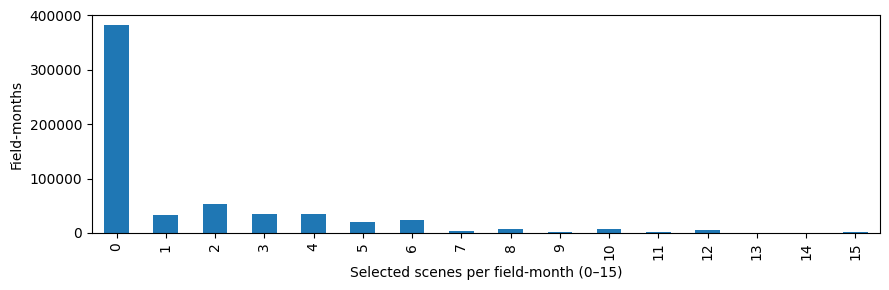

In [12]:
coverage_paths=[str(OUT/f"top15_dev_{s}/monthly_coverage.parquet") for s in SCHEMAS]
support=con.execute("""SELECT selected_scenes,count(*) field_months
FROM read_parquet(?) GROUP BY 1 ORDER BY 1""",[coverage_paths]).df()
ax=support.plot.bar(x="selected_scenes",y="field_months",legend=False,figsize=(9,3))
ax.set(xlabel="Selected scenes per field-month (0–15)",ylabel="Field-months")
plt.tight_layout(); plt.show()

## 6. Outputs

| File under ignored data/clean | Meaning |
|---|---|
| top15_dev_raw_v1/ and top15_dev_raw_oaf5/scene_decisions.parquet | One row per sampled field-scene candidate with keep/review/reject, reason and quality evidence. |
| top15_dev_raw_*/monthly_top15.parquet | Up to 15 ranked qualifying scenes per field-month, with score and scene identity. |
| top15_dev_raw_*/monthly_coverage.parquet | All scheduled field-months, including missing images and shortfall to 15. |
| top15_dev_features_*/monthly.parquet | Median bands of the selected images and their support count. |
| top15_dev_features_*/selected_scenes.parquet | Converted reflectances of the selected scene records before aggregation. |
| top15_model_ready.parquet | One row per eligible unlocked development field, with official folds and yield metadata. |
| Each summary.json | Parameters, scope and counts. |

The private database and generated data files stay in the ignored data folder. The README links to the separately shared compact model table.

## Current executed run

For the official unlocked development cohort, the screen examined **4,124,919 sampled field-scene candidate records** and selected **928,711** records across **613,896 scheduled field-months**. Of those months, **1,920** had all 15 qualifying scenes and **381,619** had none. These are field-scene records, not unique satellite files. The model table has **25,579 fields across eight countries**. These counts differ from the older MD because that run also screened fields outside this development cohort. The executed cells above reproduce the counts from the two new raw schemas.

## 7. Limits and interpretation


| Not yet verified | Why it matters |
|---|---|
| GPS-point field purity and neighboring trees, roads, or fields | Most source locations are points, so a clear pixel may still mix several land covers. |
| Thin haze and aerosol thresholds | `aot` and `wvp` are retained in candidate records but are not used as automatic rejection rules; meaningful thresholds require product-specific validation. |
| Full-season phenological coverage and temporal outliers | This procedure ranks scenes within each month. A separate sequence-level review is needed to judge whether key growth stages are observed and whether sudden changes are artifacts. |
| Reliability of planting and harvest dates | Date-based inclusion is provisional because source dates are not independently verified for every dataset. |

The screen is a reproducible image-selection proposal, not yet an approved final training dataset. Scarce or genuinely low-yield crops must not be removed simply because their vegetation indices are low.


The current run uses the new full database's **eligible development cohort**, so its counts differ from the older MD's all-field run. A good optical screen is a hypothesis about useful predictors; this notebook does not claim that it improves yield-prediction accuracy. It never excludes a crop for low NDVI or low measured yield.